# Analyse des annotations Qwen3.8 Gyro-S

Ce notebook se concentre exclusivement sur les lignes d’annotations produites par Qwen3.8 Gyro-S. Il analyse leur couverture, la répartition des taxonomies et de la qualité, puis montre des exemples aléatoires avec leurs images et leurs étiquettes. Les annotations sont des prédictions automatiques : `auto_labeled` ne signifie pas qu’elles ont été validées par une personne.


In [25]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import base64
import html
import json
import os
import random
from io import BytesIO

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from IPython.display import HTML, display
from huggingface_hub import HfApi, hf_hub_download

DATASET_REPO = 'ethanzxv/pixelart-dataset'
ANNOTATION_FILE_OVERRIDE = None  # Optionnel : chemin JSONL exact dans le dépôt HF.
HF_TOKEN = os.environ.get('HF_TOKEN') or os.environ.get('HUGGINGFACE_HUB_TOKEN') or True

# Racine locale du projet et JSONL produit par le run courant.
cwd = Path.cwd().resolve()
project_roots = [p for p in (cwd, *cwd.parents) if (p / 'notebook/dataset').is_dir()]
PROJECT_ROOT = project_roots[0] if project_roots else cwd
LOCAL_ANNOTATION_CANDIDATES = [
    PROJECT_ROOT / 'notebook/dataset/taxonomy/taxonomy_work/annotations_v3_4_exact_palette.jsonl',
    PROJECT_ROOT / 'notebook/dataset/taxonomy/taxonomy_work/annotations_v3_4_full_color.jsonl',
]
LOCAL_ANNOTATIONS = next((candidate for candidate in LOCAL_ANNOTATION_CANDIDATES if candidate.is_file()), LOCAL_ANNOTATION_CANDIDATES[0])

# Priorité : override explicite, fichier vivant local, puis snapshot Qwen3.8 le plus récent sur HF.
if ANNOTATION_FILE_OVERRIDE:
    annotation_path = Path(hf_hub_download(repo_id=DATASET_REPO, repo_type='dataset', filename=ANNOTATION_FILE_OVERRIDE, token=HF_TOKEN))
    annotation_source = ANNOTATION_FILE_OVERRIDE
elif LOCAL_ANNOTATIONS.is_file():
    annotation_path = LOCAL_ANNOTATIONS
    annotation_source = f'workspace · {LOCAL_ANNOTATIONS}'
else:
    api = HfApi(token=HF_TOKEN)
    files = api.list_repo_files(DATASET_REPO, repo_type='dataset')
    remote_candidates = [
        name for name in files
        if name.endswith('.jsonl') and (
            name.startswith('annotations/dataset_lab_sync/')
            or name.startswith('annotations/taxonomy_runs/')
        )
    ]
    remote_candidates.sort(reverse=True)
    annotation_path = None
    annotation_source = None
    for remote_name in remote_candidates:
        downloaded = Path(hf_hub_download(repo_id=DATASET_REPO, repo_type='dataset', filename=remote_name, token=HF_TOKEN))
        try:
            with downloaded.open(encoding='utf-8') as stream:
                first = next((json.loads(line) for line in stream if line.strip()), {})
            model_name = str(first.get('model', '')).lower()
            if 'qwen3.8' in model_name and 'gyro' in model_name:
                annotation_path, annotation_source = downloaded, remote_name
                break
        except (OSError, json.JSONDecodeError):
            continue
    if annotation_path is None:
        raise FileNotFoundError('Aucun JSONL Qwen3.8 Gyro-S trouvé localement ou dans les snapshots HF.')

# Snapshot cohérent du JSONL : une éventuelle dernière ligne incomplète est ignorée.
qwen_rows = []
with annotation_path.open('rb') as stream:
    while True:
        line = stream.readline()
        if not line or not line.endswith(b'\n'):
            break
        if line.strip():
            qwen_rows.append(json.loads(line))
qwen_rows = [
    row for row in qwen_rows
    if 'qwen3.8' in str(row.get('model', '')).lower()
    and 'gyro' in str(row.get('model', '')).lower()
]
if not qwen_rows:
    raise ValueError(f'Aucune annotation Qwen3.8 Gyro-S dans {annotation_source}')

print(f'{len(qwen_rows):,} lignes Qwen3.8 Gyro-S · {len({r.get("asset_id") for r in qwen_rows}):,} asset_id uniques')
print('Source :', annotation_source)


4,918 lignes Qwen3.8 Gyro-S · 4,918 asset_id uniques
Source : workspace · /home/eth/Documents/Github/iris-pixelart/notebook/dataset/taxonomy/taxonomy_work/annotations_v3_4_exact_palette.jsonl


## État général des annotations

Les compteurs portent sur le JSONL Qwen3.8 chargé ci-dessus. Les doublons sont calculés sur `asset_id` ; les champs manquants et les statuts automatiques sont exposés séparément.


In [26]:
asset_ids = [row.get('asset_id') for row in qwen_rows]
model_counts = Counter(row.get('model', '(absent)') for row in qwen_rows)
review_counts = Counter(row.get('review_status', '(absent)') for row in qwen_rows)
quality_counts = Counter(row.get('labels', {}).get('visual_quality', '(absent)') for row in qwen_rows)
rework_counts = Counter(row.get('need_rework', '(absent)') for row in qwen_rows)
timestamps = [row.get('annotated_at_utc') for row in qwen_rows if row.get('annotated_at_utc')]
summary = pd.DataFrame([
    ('Lignes Qwen3.8 Gyro-S', len(qwen_rows)),
    ('asset_id uniques', len(set(asset_ids))),
    ('asset_id dupliqués', len(asset_ids) - len(set(asset_ids))),
    ('Première annotation (UTC)', min(timestamps) if timestamps else 'inconnue'),
    ('Dernière annotation (UTC)', max(timestamps) if timestamps else 'inconnue'),
    ('Modèles', ', '.join(f'{k}: {v}' for k, v in model_counts.items())),
], columns=['Mesure', 'Valeur'])
display(summary)
print('Statuts de revue :', dict(review_counts))
print('Qualité visuelle :', dict(quality_counts))
print('need_rework :', dict(rework_counts))


,Mesure,Valeur
0,Lignes Qwen3.8 Gyro-S,4918
1,asset_id uniques,4918
2,asset_id dupliqués,0
3,Première annotation (UTC),2026-11-10T09:53:58.770099+00:00
4,Dernière annotation (UTC),2026-11-12T11:46:50.525552+00:00
5,Modèles,qwen3.8-flash-next-gyro-gyro-s: 4918


Statuts de revue : {'auto_labeled': 4918}
Qualité visuelle : {'clean': 4851, 'minor_issues': 54, 'unknown': 5, 'needs_rework': 8}
need_rework : {False: 4905, None: 5, True: 8}


## Répartition des taxonomies

Chaque graphique présente jusqu’aux 12 valeurs les plus fréquentes d’un champ. Les listes, comme `dominant_color_families`, comptent une image au plus une fois par valeur. `unknown` et `not_applicable` sont visibles dans les répartitions, car ils renseignent la couverture réelle du modèle.


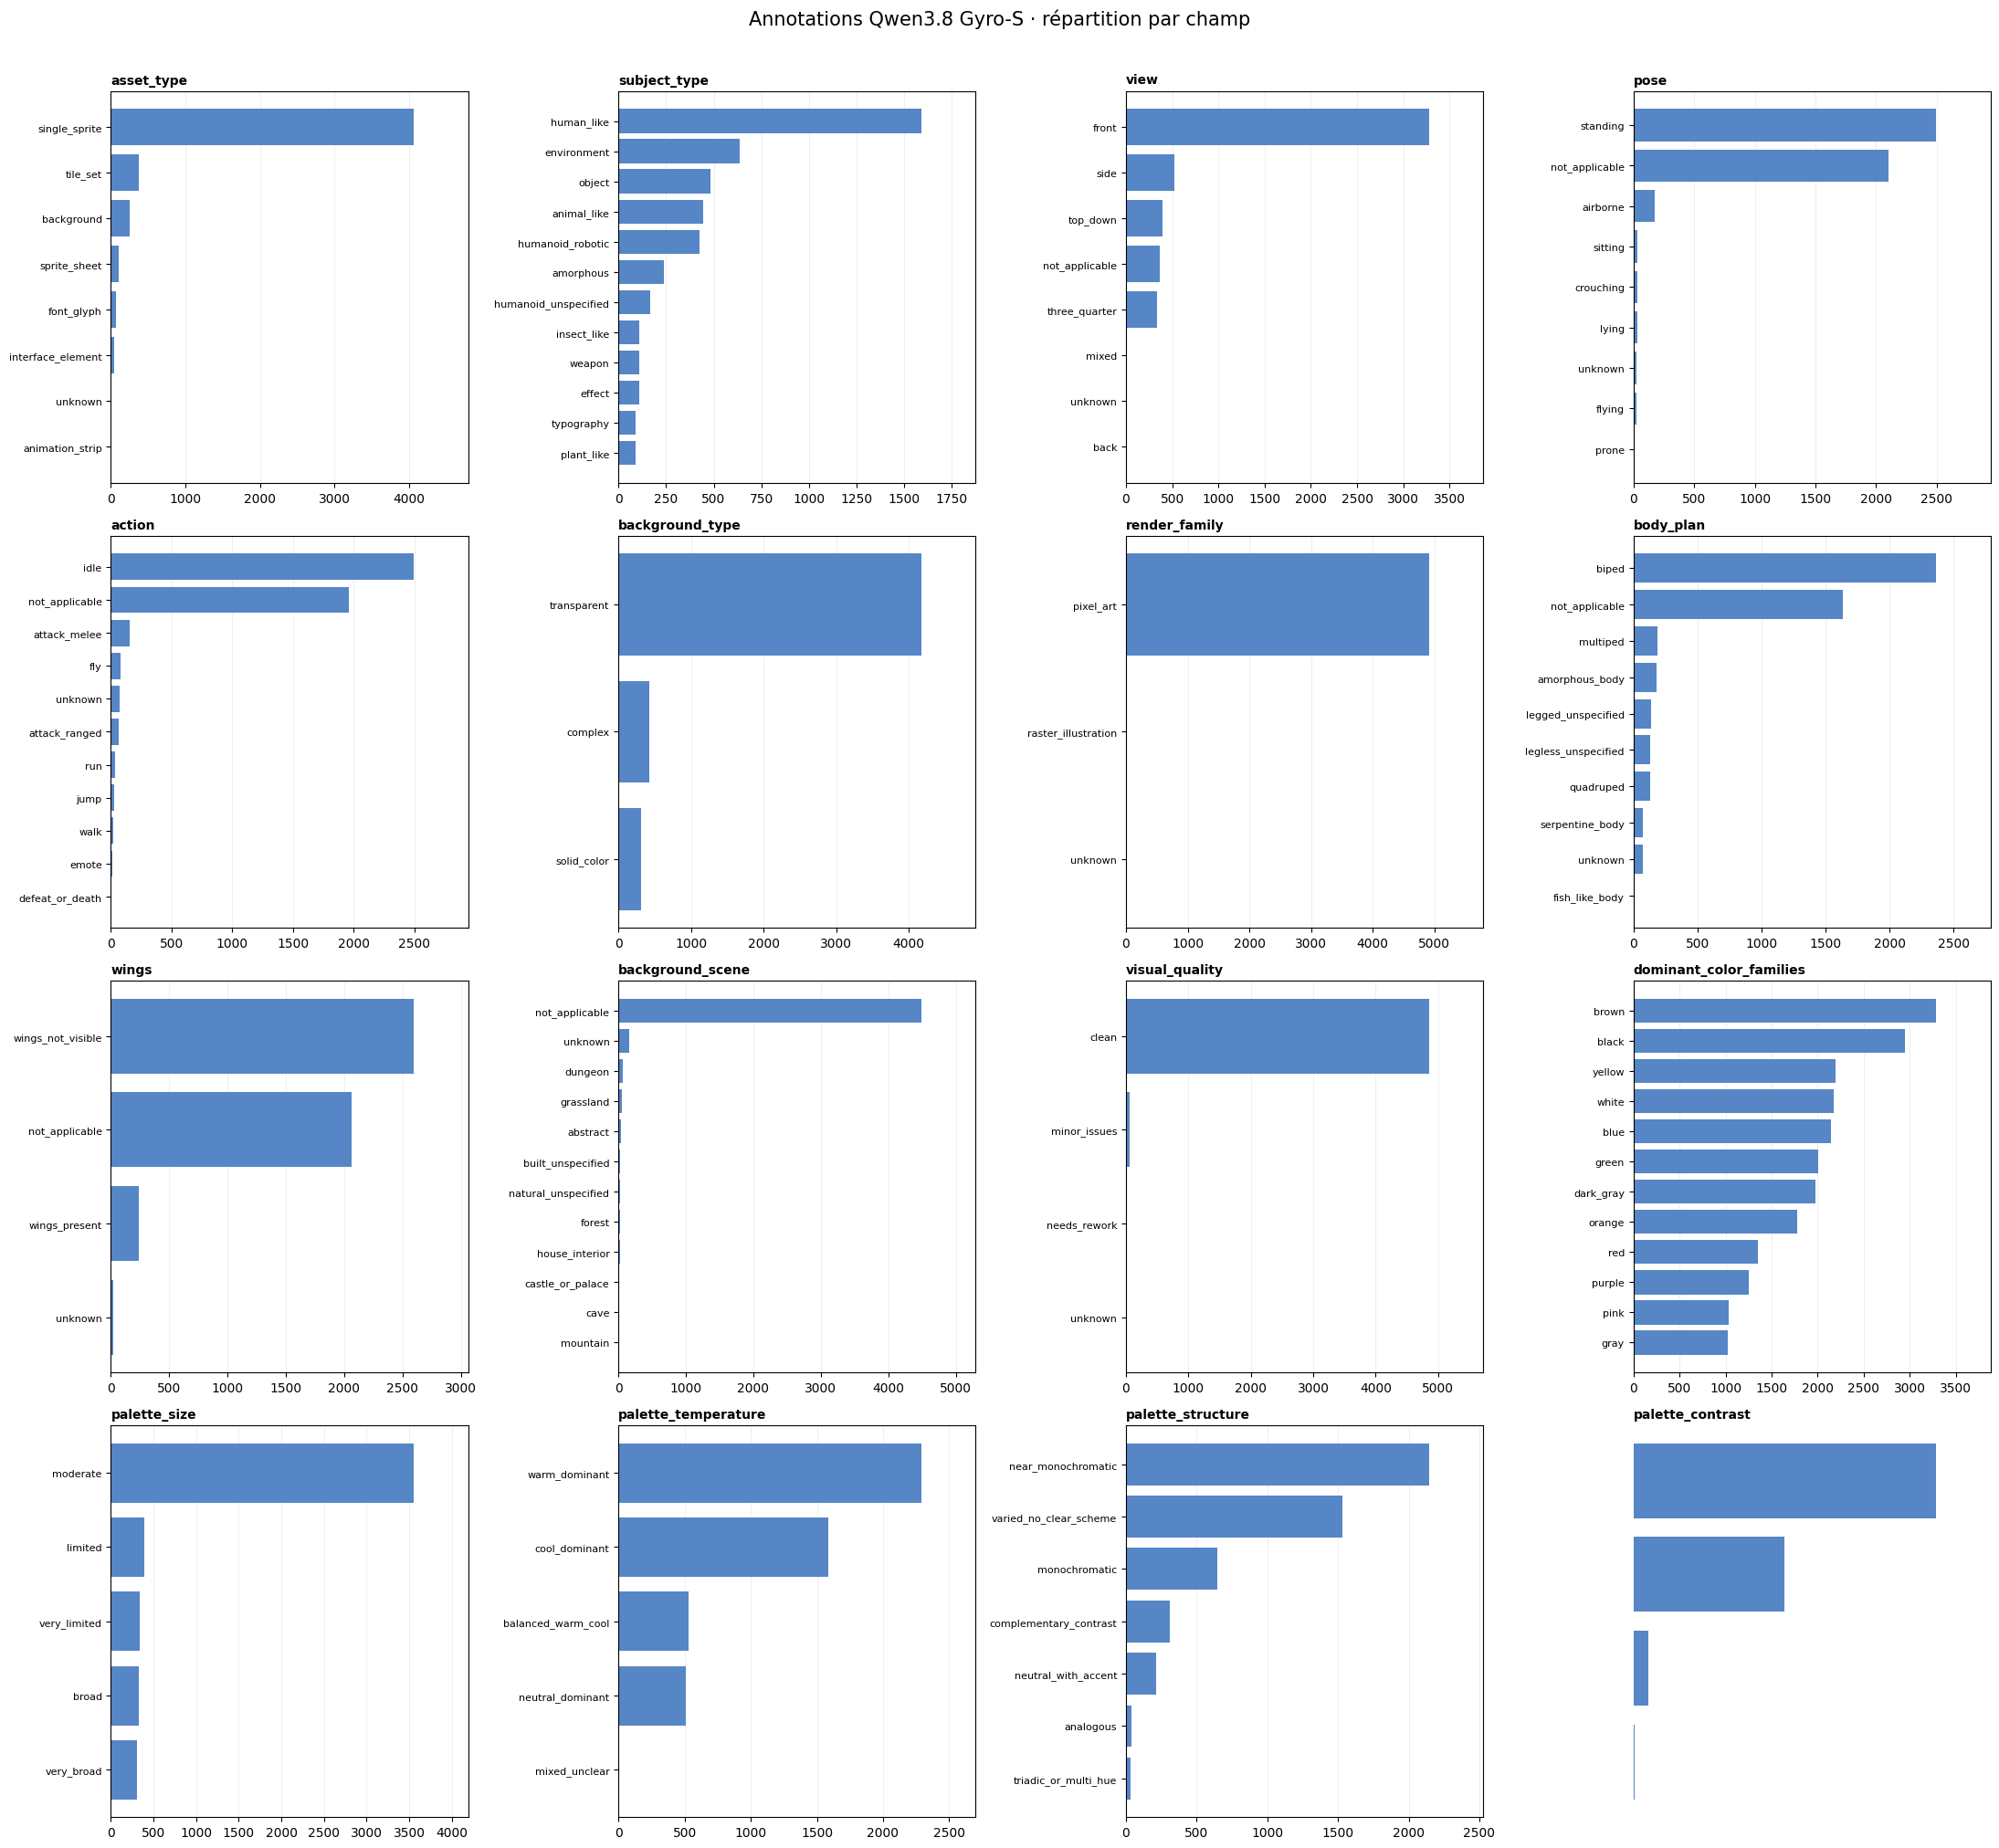

In [27]:
TAXONOMY_FIELDS = [
    'asset_type', 'subject_type', 'view', 'pose', 'action',
    'background_type', 'render_family', 'body_plan', 'wings',
    'background_scene', 'visual_quality', 'dominant_color_families',
    'palette_size', 'palette_temperature', 'palette_structure', 'palette_contrast',
]

def values_for(row, field):
    value = row.get('labels', {}).get(field)
    values = value if isinstance(value, list) else [value]
    return [str(value) if value is not None else '(absent)' for value in values]

fig, axes = plt.subplots(4, 4, figsize=(22, 20))
for ax, field in zip(axes.flat, TAXONOMY_FIELDS):
    counts = Counter()
    for row in qwen_rows:
        counts.update(set(values_for(row, field)))
    top = counts.most_common(12)
    if top:
        names, numbers = zip(*top)
        ax.barh(list(names)[::-1], list(numbers)[::-1], color='#5686c5')
        ax.set_xlim(0, max(numbers) * 1.18)
    ax.set_title(field, loc='left', fontsize=10, fontweight='bold')
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
axes.flat[-1].axis('off')
fig.suptitle('Annotations Qwen3.8 Gyro-S · répartition par champ', fontsize=15, y=1.01)
fig.tight_layout()
plt.show()


## Qualité, rework et couverture

`visual_quality` décrit l’état visuel estimé par Qwen. `need_rework` est une autre prédiction ; les deux valeurs sont comparées pour repérer les éventuelles incohérences. Les annotations `auto_labeled` restent à vérifier même si elles sont évaluées `clean`.


In [28]:
quality_audit = Counter(
    (row.get('labels', {}).get('visual_quality', '(absent)'), row.get('need_rework', '(absent)'))
    for row in qwen_rows
)
audit_df = pd.DataFrame([
    {'visual_quality': quality, 'need_rework': rework, 'images': count}
    for (quality, rework), count in quality_audit.most_common()
])
display(audit_df)

coverage_rows = []
for field in TAXONOMY_FIELDS:
    missing = sum(not row.get('labels', {}).get(field) for row in qwen_rows)
    unknown = sum('unknown' in values_for(row, field) for row in qwen_rows)
    not_applicable = sum('not_applicable' in values_for(row, field) for row in qwen_rows)
    coverage_rows.append({
        'champ': field,
        'manquant': missing,
        'unknown': unknown,
        'not_applicable': not_applicable,
        'renseigné': len(qwen_rows) - missing,
    })
display(pd.DataFrame(coverage_rows).set_index('champ'))


,visual_quality,need_rework,images
0,clean,False,4851
1,minor_issues,False,54
2,needs_rework,True,8
3,unknown,None,5


,manquant,unknown,not_applicable,renseigné
champ,,,,
asset_type,0,12,0,4918
subject_type,0,16,0,4918
view,0,11,362,4918
pose,0,24,2101,4918
action,0,71,1960,4918
background_type,0,0,0,4918
render_family,0,1,0,4918
body_plan,0,72,1634,4918
wings,0,17,2063,4918


## Couleurs exactes

Les distributions de couleurs, les palettes complètes et les associations de codes hex sont disponibles dans [analyse_hex_colors.ipynb](analyse_hex_colors.ipynb).

## Exemples aléatoires d’annotations

Change `N_EXEMPLES` ou `GRAINE` pour parcourir un autre échantillon. La grille Matplotlib utilise deux colonnes pour agrandir les sprites et rendre lisible la caption Qwen placée sous chaque image, suivie de la source et des tags principaux.


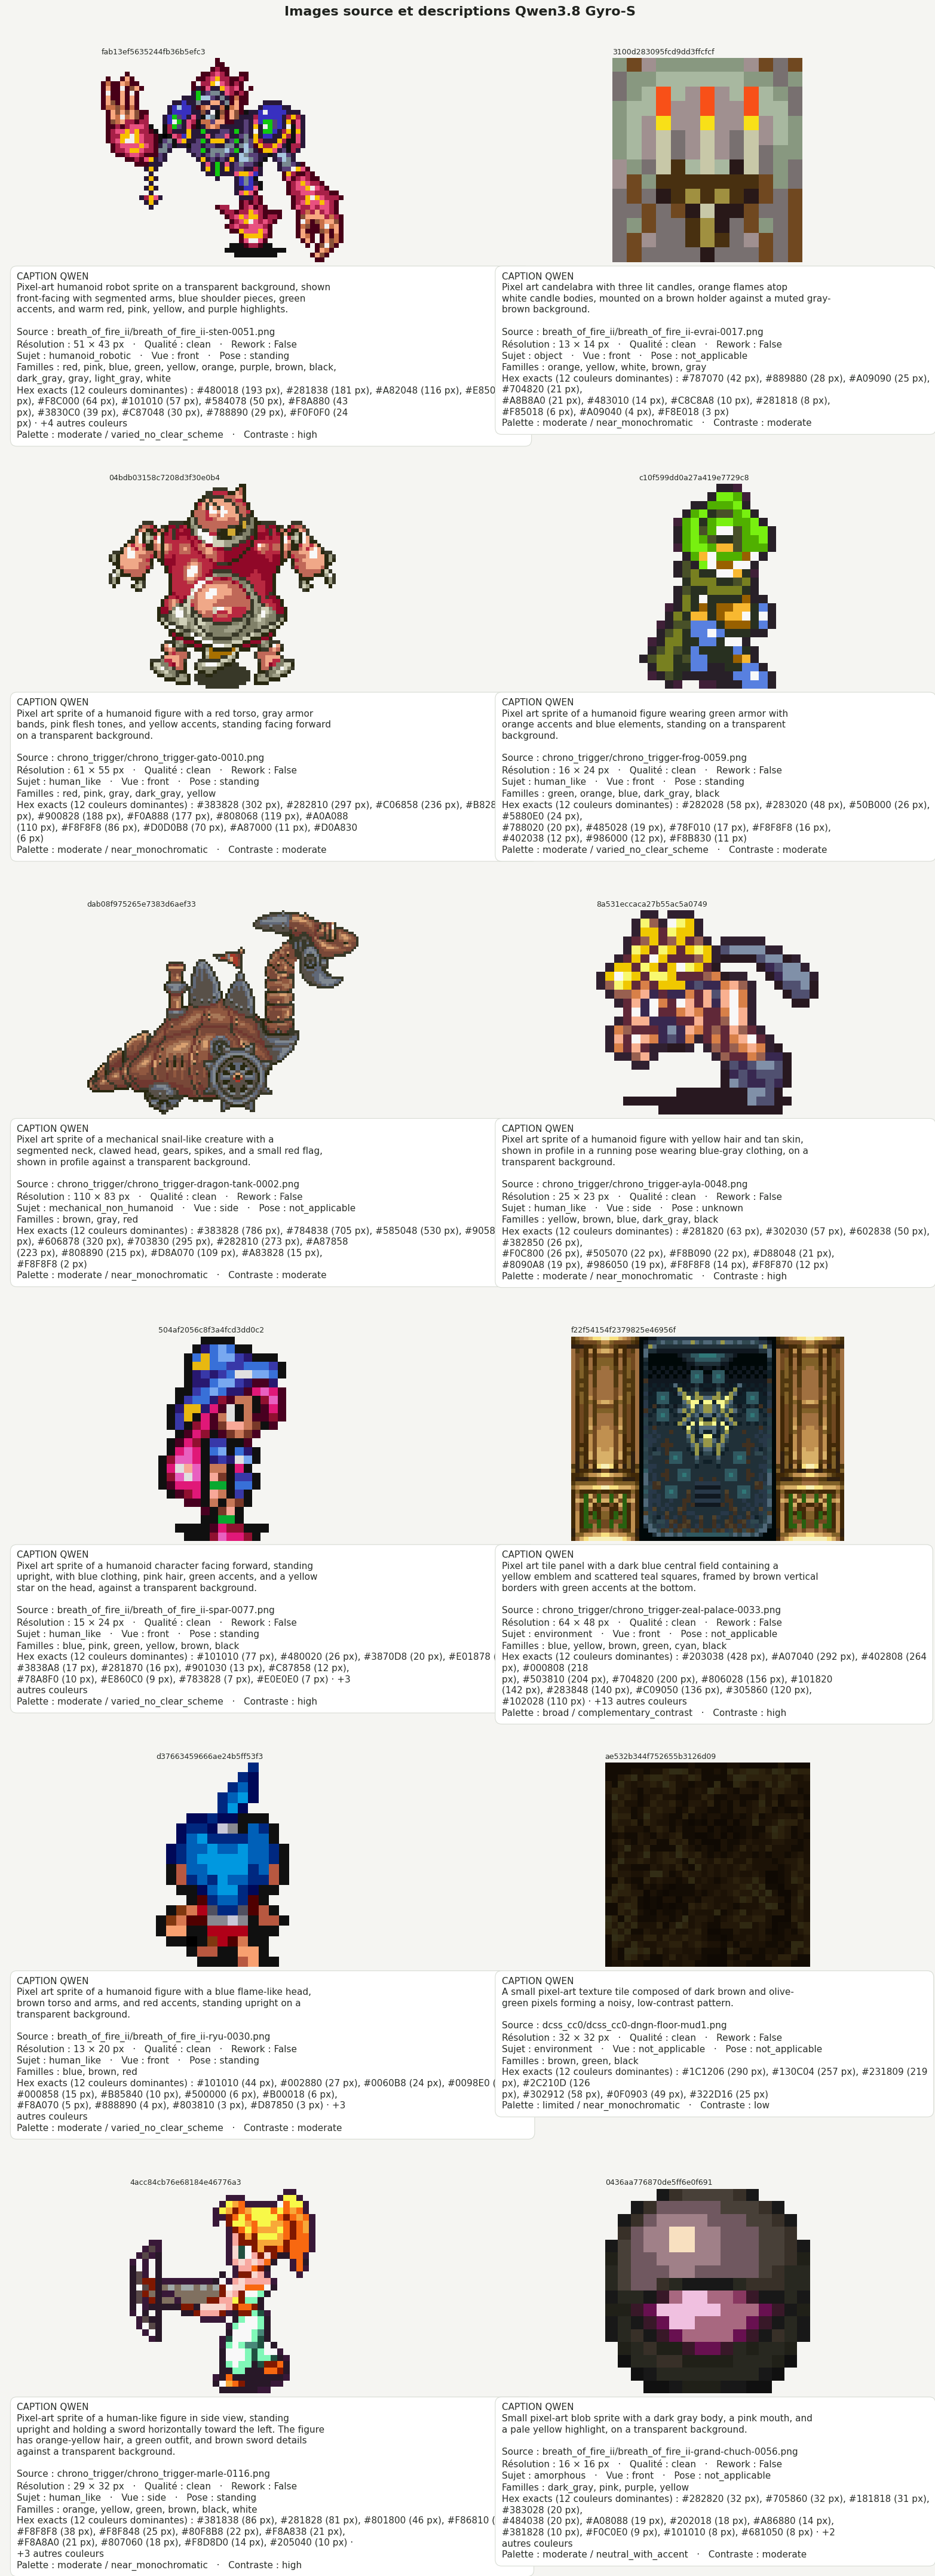

In [30]:
# Charge le token depuis l’environnement ou les fichiers .env connus, sans jamais l’imprimer.
import textwrap
for env_file in (PROJECT_ROOT / '.env', PROJECT_ROOT / 'training/.env', Path.home() / 'iris-sprite-lora/training/.env'):
    if not env_file.is_file():
        continue
    for line in env_file.read_text(encoding='utf-8').splitlines():
        key, separator, value = line.partition('=')
        if separator and key.strip() in {'HF_TOKEN', 'HUGGINGFACE_HUB_TOKEN'}:
            os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))
            break
HF_TOKEN = os.environ.get('HF_TOKEN') or os.environ.get('HUGGINGFACE_HUB_TOKEN') or True

N_EXEMPLES = 12
GRAINE = 42
TELECHARGER_IMAGES_HF = True  # False pour n’afficher que les images déjà en cache.

cache_roots = [PROJECT_ROOT / 'notebook/training/iris_sprite_lora_work/source_images']
image_sample = random.Random(GRAINE).sample(qwen_rows, min(N_EXEMPLES, len(qwen_rows)))
image_records = []
for row in image_sample:
    source = row.get('source', {})
    relative_path = str(source.get('relative_path', '')).replace('\\', '/')
    root_name = str(source.get('root', 'data'))
    image_path = next((root / root_name / relative_path for root in cache_roots if (root / root_name / relative_path).is_file()), None)
    if image_path is None and TELECHARGER_IMAGES_HF and relative_path:
        try:
            image_path = Path(hf_hub_download(
                repo_id=DATASET_REPO, repo_type='dataset',
                filename=f'data/{relative_path}', token=HF_TOKEN,
            ))
        except Exception:
            image_path = None
    image_records.append((row, image_path))

# Matplotlib : chaque sprite a une zone de texte distincte juste en dessous.
import matplotlib.pyplot as plt

columns = 2
rows_count = (len(image_records) + columns - 1) // columns
fig = plt.figure(figsize=(16, rows_count * 7.3), facecolor='#f5f5f2')
outer = fig.add_gridspec(rows_count, columns, wspace=0.12, hspace=0.16)
for index, (row, image_path) in enumerate(image_records):
    outer_row, outer_col = divmod(index, columns)
    card = outer[outer_row, outer_col].subgridspec(2, 1, height_ratios=[3.0, 2.3], hspace=0.035)
    image_ax = fig.add_subplot(card[0])
    text_ax = fig.add_subplot(card[1])
    image_ax.set_facecolor('#e9e9e5')
    image_ax.axis('off')
    asset_id = str(row.get('asset_id', '(id absent)'))
    source_path = str(row.get('source', {}).get('relative_path', '(source absente)'))
    if image_path is not None and image_path.is_file():
        try:
            with Image.open(image_path) as image:
                image_ax.imshow(image.convert('RGBA'), interpolation='nearest')
                dimensions = f'{image.width} × {image.height} px'
        except OSError:
            dimensions = 'image illisible'
            image_ax.text(.5, .5, dimensions, ha='center', va='center', transform=image_ax.transAxes)
    else:
        dimensions = 'image indisponible'
        image_ax.text(.5, .5, dimensions, ha='center', va='center', transform=image_ax.transAxes)
    image_ax.set_title(asset_id, fontsize=9, loc='left', pad=5, color='#262a25')

    labels = row.get('labels', {})
    caption = str(row.get('caption_candidate') or 'Description Qwen absente.')
    colors = labels.get('dominant_color_families') or []
    color_text = ', '.join(map(str, colors)) if isinstance(colors, list) else str(colors or '—')
    measured_palette = row.get('color_measurements', {}).get('palette_hex', [])
    exact_colors = [
        f"{entry.get('hex')} ({entry.get('pixel_count', 0):,} px)"
        for entry in measured_palette[:12] if entry.get('hex')
    ]
    exact_palette_text = ', '.join(exact_colors) or 'non mesurée'
    if len(measured_palette) > len(exact_colors):
        exact_palette_text += f" · +{len(measured_palette) - len(exact_colors)} autres couleurs"
    description = (
        f"CAPTION QWEN\n{textwrap.fill(caption, width=68)}\n\n"
        f"Source : {textwrap.fill(source_path, width=68)}\n"
        f"Résolution : {dimensions}   ·   Qualité : {labels.get('visual_quality', 'inconnue')}   ·   Rework : {row.get('need_rework', 'inconnu')}\n"
        f"Sujet : {labels.get('subject_type', '—')}   ·   Vue : {labels.get('view', '—')}   ·   Pose : {labels.get('pose', '—')}\n"
        f"Familles : {textwrap.fill(color_text, width=68)}\n"
        f"Hex exacts (12 couleurs dominantes) : {textwrap.fill(exact_palette_text, width=68)}\n"
        f"Palette : {labels.get('palette_size', '—')} / {labels.get('palette_structure', '—')}   ·   Contraste : {labels.get('palette_contrast', '—')}"
    )
    text_ax.axis('off')
    text_ax.set_facecolor('white')
    text_ax.text(
        0.025, 0.98, description, transform=text_ax.transAxes,
        ha='left', va='top', fontsize=11, color='#292d28',
        linespacing=1.3, wrap=True,
        bbox={'boxstyle':'round,pad=0.7', 'facecolor':'white', 'edgecolor':'#d8dcd4', 'linewidth':0.8},
    )

for index in range(len(image_records), rows_count * columns):
    ax = fig.add_subplot(outer[index // columns, index % columns])
    ax.axis('off')
fig.suptitle('Images source et descriptions Qwen3.8 Gyro-S', fontsize=16, fontweight='bold', y=.995, color='#20231f')
fig.subplots_adjust(left=.025, right=.985, top=.975, bottom=.02)
display(fig)
plt.close(fig)
